# EmPath — full four-ZIP GeoAI tree-cover analysis

This expands the four demonstration tiles to the **complete 75023, 75024, 75025 and 75074 ZCTA union** (about 124 km²). It uses lossless RGB windows from USDA NAIP 2022 at 60 cm and the pretrained Restor TCD SegFormer-B0 model. No Google imagery, training from scratch, or ArcGIS Pro/QGIS is required.

The model predicts **tree cover**, not all vegetation, actual shade, temperature, or walking safety. Transfer from 10 cm model-training imagery to 60 cm NAIP imagery remains unvalidated locally. Full geographic coverage does not establish accuracy.

Use Python (EmPath). A separate native Apple Silicon worker uses PyTorch/MPS for inference while the existing EmPath environment handles GIS. Completed prediction tiles are cached and reused. Set `REBUILD_SUMMARIES=True` only when you deliberately need to recompute summaries. Use a new output/cache folder if model weights, source year, resolution, grid or study boundaries change. Do not delete caches while a run is active.

In [1]:
from pathlib import Path
import sys,json,os
ROOT=Path.cwd()
if not (ROOT/'scripts').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
from IPython.display import display
import pandas as pd
OUT=ROOT/'output/geoai_full_scope'

## 1. Inspect the full-area plan
The grid uses 896-pixel cores and 64-pixel context margins. All source imagery is from 2022 to avoid silently mixing years. The inventory is checked for footprint coverage; actual observed-pixel coverage is measured after inference.

In [2]:
from full_scope_geoai import plan
cfg=plan()
display({k:v for k,v in cfg.items() if k!='tiles'})
print('Inference tiles:',len(cfg['tiles']))

{'resolution_m': 0.6,
 'core_pixels': 896,
 'halo_pixels': 64,
 'width': 36204,
 'height': 23505,
 'transform': [0.6, 0.0, 699501.0, 0.0, -0.6, 3667465.8],
 'model': 'restor/tcd-segformer-mit-b0',
 'year': 2022,
 'scope_zips': ['75023', '75024', '75025', '75074']}

Inference tiles: 505


## 2. Run or resume inference

The first run retrieves several hundred imagery windows and runs the pretrained network. This can take substantial time. Tile GeoTIFFs contain class predictions and rounded tree probabilities; original RGB crop dates and item IDs are recorded. Missing pixels remain unknown.

The native worker environment was prepared for this machine. To recreate it:

```
uv venv --python /usr/local/bin/python3 .venv-geoai-arm
uv pip install --python .venv-geoai-arm/bin/python torch==2.7.1 transformers==4.44.2 'numpy<2' pillow safetensors
```

The worker is launched explicitly as ARM64, avoiding the existing Rosetta Python's architecture mismatch. Model weights are cached in `data/models/restor-tcd-b0/`.

If a run is already active, the next cell reports progress instead of starting a duplicate. Re-run the progress cell to refresh.

In [3]:
active=OUT/'active_run.json'
busy=False
if active.exists():
    info=json.loads(active.read_text())
    try:
        os.kill(int(info['pid']),0)
        busy=True
    except ProcessLookupError:
        pass
if busy:
    print('An existing full-area run is active. Do not start another worker.')
elif all((OUT/'tiles'/(t['id']+'.tif')).exists() for t in cfg['tiles']):
    print('All prediction tiles already exist; reusing completed inference.')
else:
    from full_scope_geoai_api import run
    run()
if (OUT/'progress.json').exists():
    display(json.loads((OUT/'progress.json').read_text()))

All prediction tiles already exist; reusing completed inference.


{'stage': 'complete',
 'source_scene_count': 12,
 'source_year': 2022,
 'scope_area_km2': 124.11950447893062,
 'updated_unix': 1794464441.3093429,
 'retrieval': 'Planetary Computer lossless RGB window API',
 'device': 'mps',
 'completed_tiles': 505,
 'total_tiles': 505,
 'summary_tiles_completed': 500,
 'inference_tiles': 505,
 'native_pixel_size_m': 0.6,
 'observed_pixels': 344776095,
 'blocks': 2862,
 'blocks_with_prediction': 2862,
 'edges': 93452,
 'edges_with_prediction': 93244,
 'tree_polygons': 40258,
 'route_comparisons_completed': True}

## 3. Check completion and summarize
Only run the full-area aggregation when every planned prediction tile exists. This creates a full-scope raster, tree polygons, per-block cover/coverage, walking-edge attributes, and a separate interactive map. It does not overwrite the published canopy layer or production graph. The combined score still uses assumed equal canopy/traffic weights.

Missing prediction tiles: 0


{'inference_tiles': 505,
 'source_year': 2022,
 'native_pixel_size_m': 0.6,
 'scope_area_km2': 124.11950447893062,
 'observed_pixels': 344776095,
 'blocks': 2862,
 'blocks_with_prediction': 2862,
 'edges': 93452,
 'edges_with_prediction': 93244,
 'tree_polygons': 40258,
 'coverage_by_zip': [{'zip': '75023',
   'blocks': 644,
   'expected_pixels': 66244097,
   'observed_pixels': 66244097,
   'coverage_pct': 100.0,
   'blocks_with_prediction': 644},
  {'zip': '75024',
   'blocks': 740,
   'expected_pixels': 94043609,
   'observed_pixels': 94043609,
   'coverage_pct': 100.0,
   'blocks_with_prediction': 740},
  {'zip': '75025',
   'blocks': 685,
   'expected_pixels': 69117397,
   'observed_pixels': 69117397,
   'coverage_pct': 100.0,
   'blocks_with_prediction': 685},
  {'zip': '75074',
   'blocks': 793,
   'expected_pixels': 115370992,
   'observed_pixels': 115370992,
   'coverage_pct': 100.0,
   'blocks_with_prediction': 793}],
 'limitations': ['Tree segmentation, not measured shade or 

,zip,blocks,expected_pixels,observed_pixels,coverage_pct,blocks_with_prediction
0,75023,644,66244097,66244097,100.0,644
1,75024,740,94043609,94043609,100.0,740
2,75025,685,69117397,69117397,100.0,685
3,75074,793,115370992,115370992,100.0,793


,zip,route,origin_node,destination_node,distance_m,detour_ratio,mean_tree_adjacency_01,cost_equivalent_m,access_verified,candidate_count
0,75023,Shortest distance,5000939117,5000924516,839.869101,1.000000,0.063350,989.815028,False,30
1,75023,Distance–canopy trade-off,5000939117,5000924516,839.869101,1.000000,0.063350,989.815028,False,30
2,75023,Tree-adjacency priority,5000939117,5000924516,868.174013,1.033702,0.066583,1022.638432,False,30
3,75024,Shortest distance,7272249381,3653446646,989.022908,1.000000,0.002142,1177.136845,False,30
4,75024,Distance–canopy trade-off,7272249381,3653446646,989.022908,1.000000,0.002142,1177.136845,False,30
5,75024,Tree-adjacency priority,7272249381,3653446646,992.520309,1.003536,0.004281,1180.894759,False,30
6,75025,Shortest distance,7229627409,7890707382,963.953683,1.000000,0.098765,1129.546046,False,30
7,75025,Distance–canopy trade-off,7229627409,7890707382,965.295245,1.001392,0.124406,1126.400182,False,30
8,75025,Tree-adjacency priority,7229627409,7890707382,965.295245,1.001392,0.124406,1126.400182,False,30
9,75074,Shortest distance,5797694583,150172848,685.806861,1.000000,0.100204,803.429730,False,30


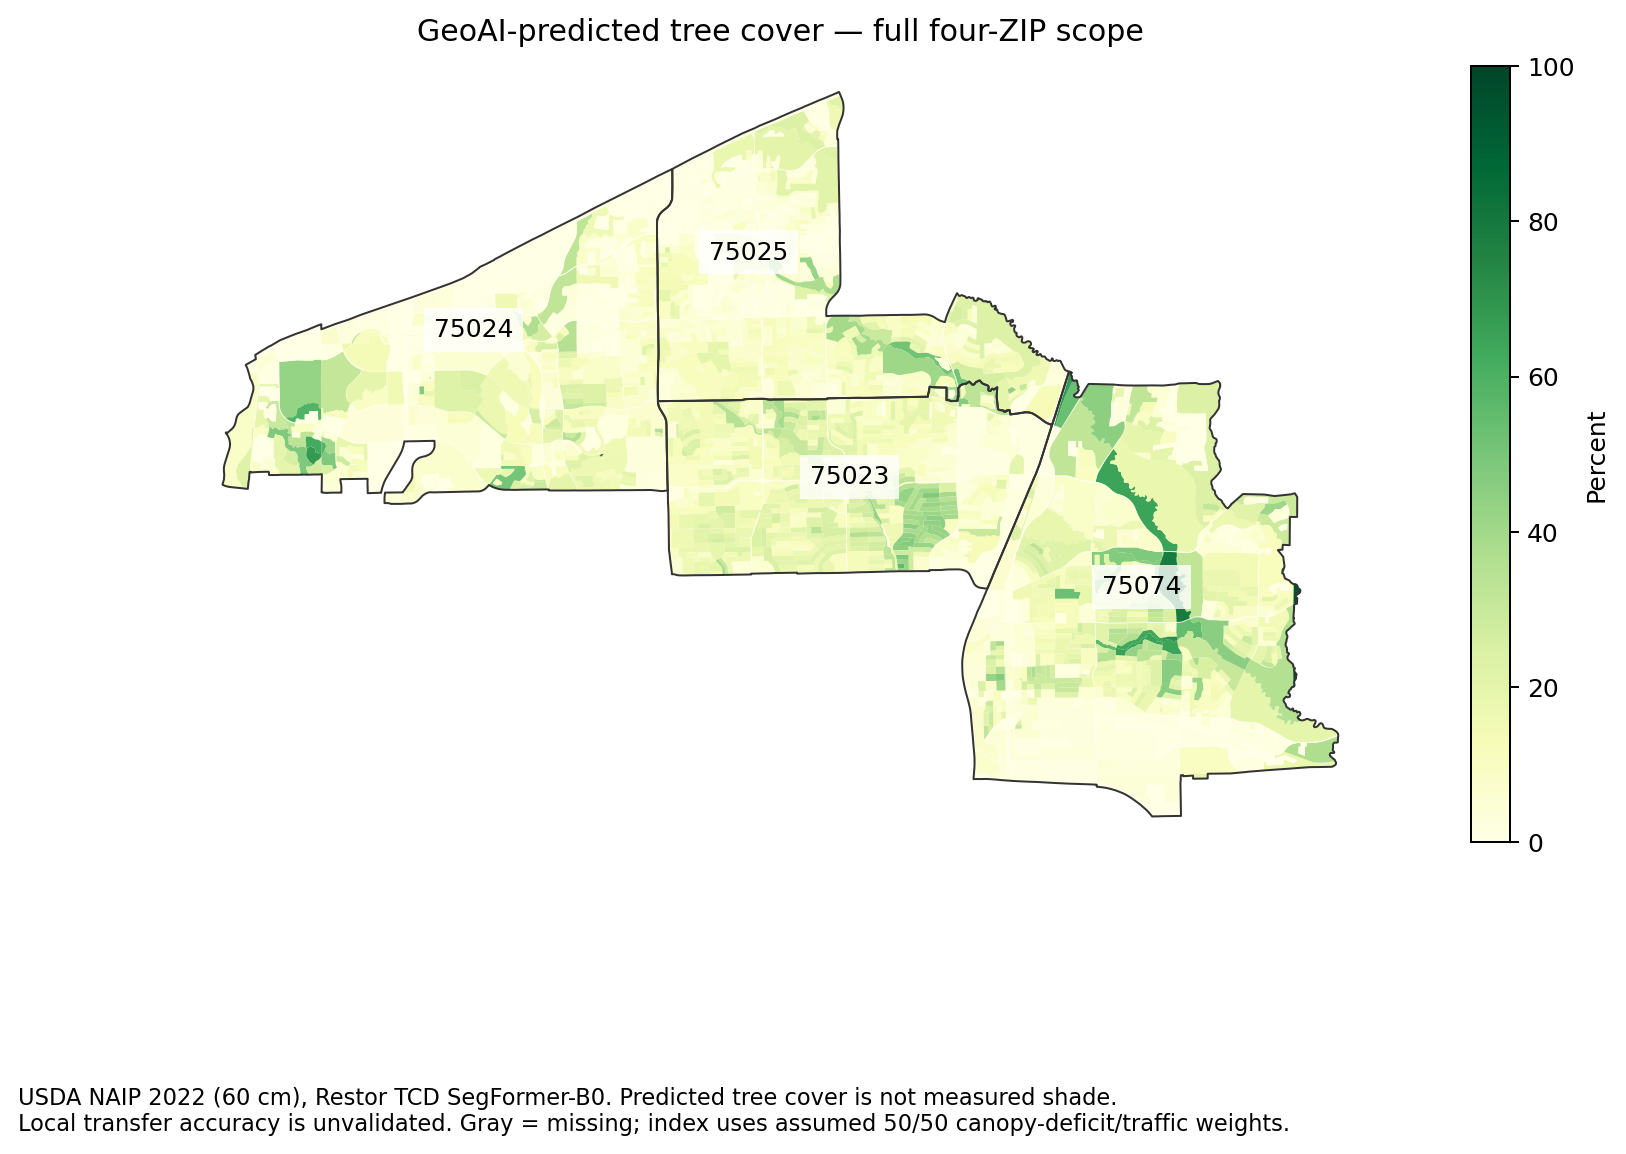

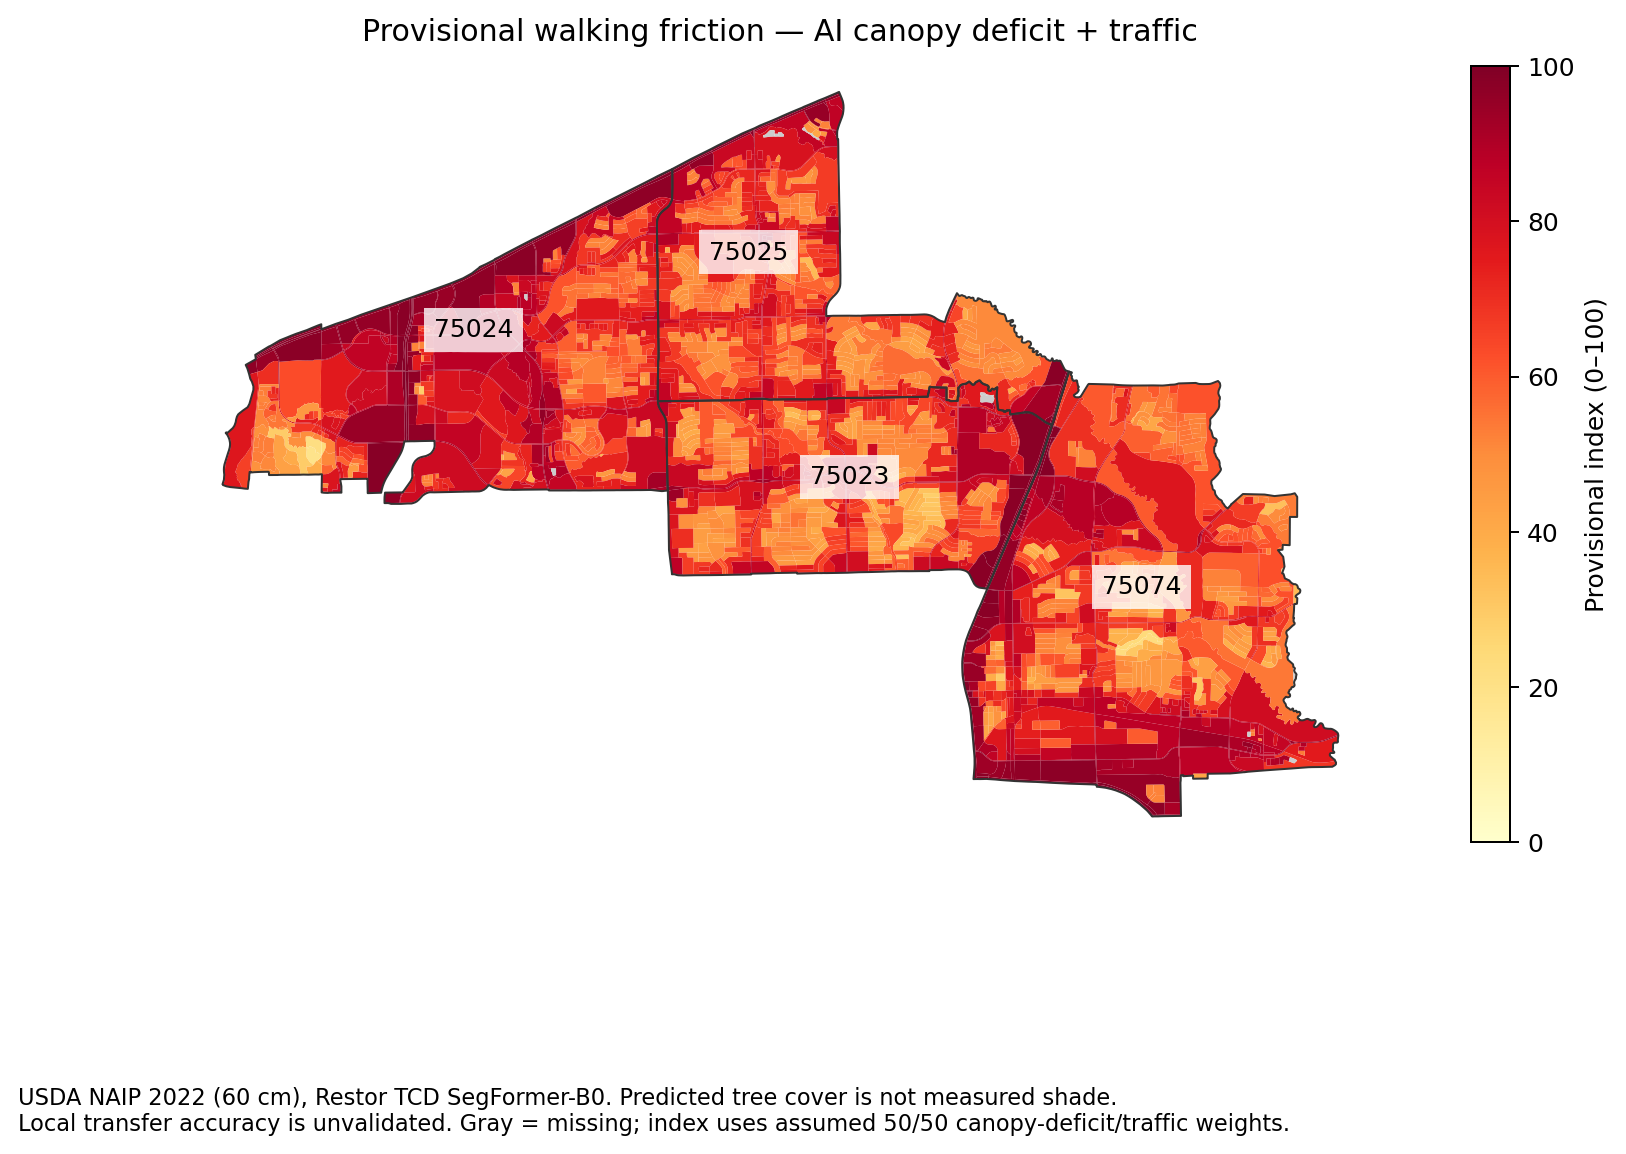

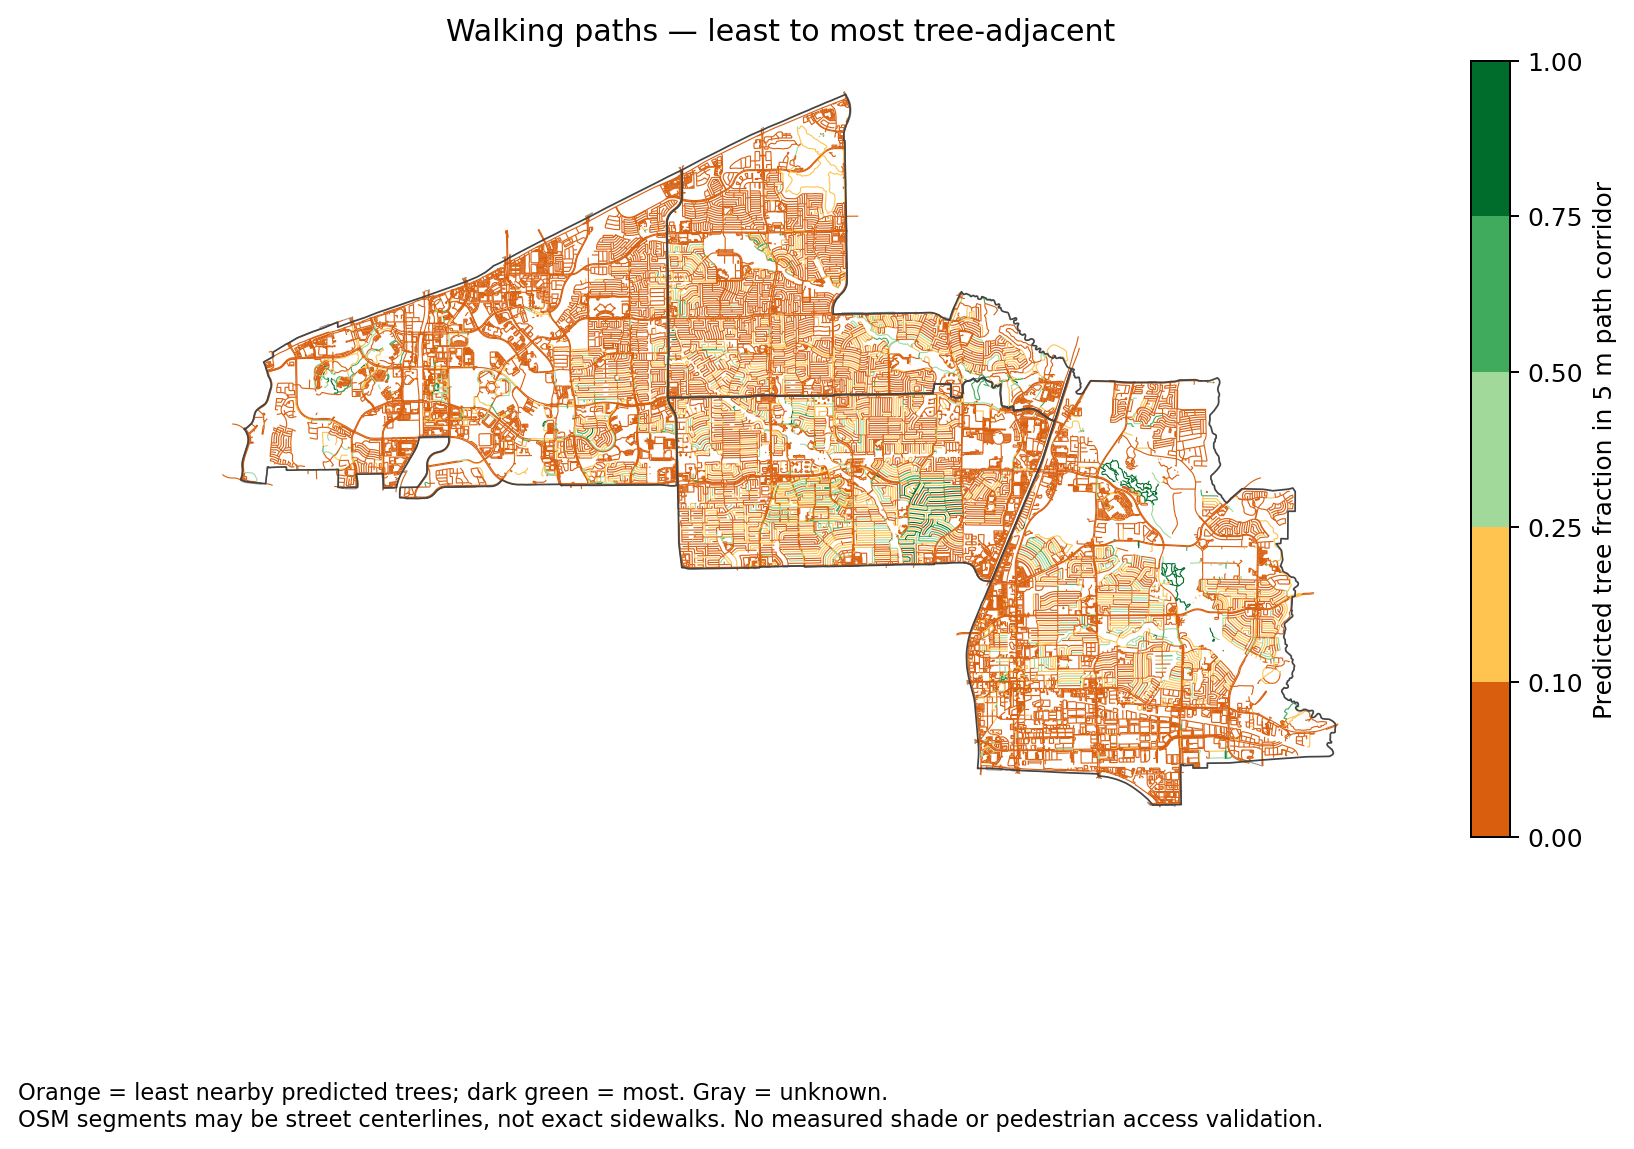

In [4]:
missing=[t['id'] for t in cfg['tiles'] if not (OUT/'tiles'/(t['id']+'.tif')).exists()]
print('Missing prediction tiles:',len(missing))
REBUILD_SUMMARIES=False
if not missing:
    if REBUILD_SUMMARIES or not (OUT/'coverage_report.json').exists():
        from summarize_full_scope_geoai import summarize,render
        report=summarize()
        from full_scope_route_comparison import run as compare_routes
        compare_routes()
        import geopandas as gpd
        render(gpd.read_file(OUT/'ai_block_environment.gpkg'),gpd.read_file(OUT/'ai_walking_edges.gpkg'))
        from preview_full_scope_geoai import main as export_figures
        export_figures()
        from build_compact_full_geoai_map import main as compact_viewer
        compact_viewer()
    report=json.loads((OUT/'coverage_report.json').read_text())
    display(report)
    display(pd.read_csv(OUT/'coverage_by_zip.csv'))
    display(pd.read_csv(OUT/'full_scope_route_comparison.csv'))
    from IPython.display import Image
    for figure in json.loads((OUT/'figure_captions.json').read_text()):
        display(Image(filename=str(OUT/figure['image']),width=900))
else:
    print('Inference is incomplete. Resume step 2; do not label the map full-coverage yet.')

## 4. Interpret and review

- **Tree-adjacency colors:** orange = least nearby predicted trees; dark green = most. Gray = unknown. The measurement uses a 5 m buffer around each OSM segment, which may be a street centerline rather than the actual sidewalk.
- A block mean can hide an exposed walking corridor. Use edge attributes for routing and block means for area summaries.
- Compare predictions with independent imagery annotations before claiming local accuracy. Geographic completeness and model accuracy are separate checks.
- Notebook 13 contains the original small-area demonstrations; this notebook also recalculates those endpoint comparisons using the complete attributed pilot network. The balanced route uses the transferred Singapore distance/sun coefficient with canopy as an unvalidated sun-exposure proxy. A separate tree-priority route maximizes mean tree adjacency among up to 30 diverse loopless candidates within 1.5× shortest distance.
- Partial image/corridor coverage is explicitly reported. Small polygons without pixel centers can have missing estimates even when source coverage is complete.

## Outputs

`output/geoai_full_scope/`: progress.json, tile_plan.json, imagery_sources.json, inputs/, tiles/, full_scope_tree_cover.tif, predicted_tree_polygons.gpkg, ai_block_environment.gpkg/CSV, ai_walking_edges.gpkg/CSV, coverage_by_zip.csv, coverage_report.json, full_scope_geoai_map.html.

## References

- [Restor TCD model and limits](https://huggingface.co/restor/tcd-segformer-mit-b0)
- [Restor TCD implementation](https://github.com/Restor-Foundation/tcd)
- [USDA NAIP](https://naip-usdaonline.hub.arcgis.com/)
- [Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/)
